# Student workbook: unbinned maximum-likelihood fit with `iminuit`

This guided hands-on notebook fits the distribution of $x=\cos\theta$ with
$f(x\mid a,b)=(1+ax+bx^2)/I(a,b)$. Work from top to bottom, completing the `TODO` items in code cells. Hints appear before each task.

Some cells are intentionally incomplete, so the notebook will not run end-to-end until you fill in the missing code. The companion solutions notebook contains a completed version.

The fit uses individual event values; histograms are for visualization.


In [3]:
# If needed, install iminuit in your environment:
!pip install iminuit

import numpy as np
import matplotlib.pyplot as plt
from iminuit import Minuit
from iminuit.cost import UnbinnedNLL

print("NumPy:", np.__version__)
import iminuit
print("iminuit:", iminuit.__version__)

NumPy: 2.4.6
iminuit: 2.33.0


## Step 0 — Load and check the sample


The original example uses a text file hosted by Heidelberg University, but in our git you can find it (https://github.com/erossi2/AnalisiDati_aa2026-27/blob/main/Likelihood%26OtherTests/data_ml_fit.txt). If the download is unavailable,
the cell creates a reproducible toy sample so that the rest of the notebook can still be run.

The fit range is fixed to $[-0.95,0.95]$, as in the original example.

In [5]:
XMIN, XMAX = -0.95, 0.95
DATA_URL = (
    "https://www.physi.uni-heidelberg.de/~reygers/lectures/2020/"
    "smipp/data_ml_fit.txt"
)

try:
    data = np.loadtxt(DATA_URL)
    data_source = "Heidelberg example dataset"
except Exception as err:
    print(f"Could not download the example data ({err}).")
    print("Generating a reproducible toy sample instead.")

    rng = np.random.default_rng(2025)
    a_true, b_true = 0.35, 0.25

    def pdf_unnormalized(x, a, b):
        return 1.0 + a*x + b*x**2

    # Rejection sampling. The envelope is evaluated on a dense grid.
    grid = np.linspace(XMIN, XMAX, 2000)
    envelope = pdf_unnormalized(grid, a_true, b_true).max()
    accepted = []
    while len(accepted) < 1000:
        candidates = rng.uniform(XMIN, XMAX, 3000)
        keep = rng.uniform(0, envelope, candidates.size) < pdf_unnormalized(
            candidates, a_true, b_true
        )
        accepted.extend(candidates[keep].tolist())
    data = np.asarray(accepted[:1000])
    data_source = "toy sample (a=0.35, b=0.25)"

data = np.asarray(data, dtype=float).ravel()
data = data[np.isfinite(data)]
data = data[(data >= XMIN) & (data <= XMAX)]

if data.size == 0:
    raise ValueError("No finite events remain inside the fit range.")

print(f"Data source: {data_source}")
print(f"Number of events in fit range: {data.size}")
print(f"Minimum / maximum: {data.min():.4f} / {data.max():.4f}")

Data source: Heidelberg example dataset
Number of events in fit range: 1000
Minimum / maximum: -0.9494 / 0.9500


## Step 1 — Explore the data


A histogram helps us understand the shape of the data. The choice of binning affects the appearance
of the histogram, but **does not affect the unbinned fit**.

### Your turn
Change the number of bins to compare a coarse and fine view. Does this affect the unbinned fit?


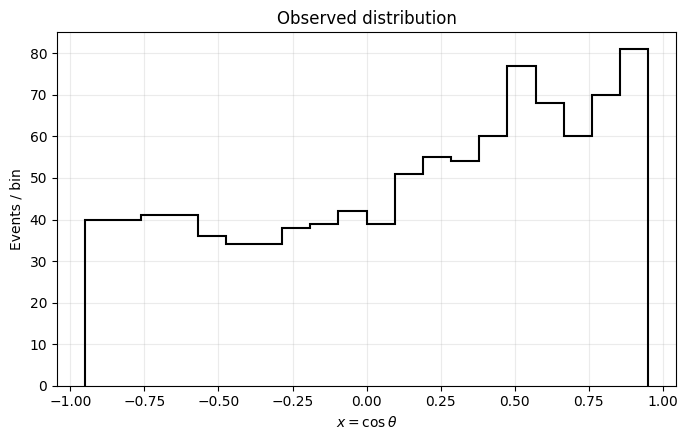

In [6]:
# TODO: choose a bin count and use it in ax.hist to display the sample.
# Hint: the data are in `data`; restrict the plot to [XMIN, XMAX].
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(data, bins=20, range=(XMIN, XMAX), histtype="step",
        color="black", linewidth=1.5)
ax.set(xlabel=r"$x=\cos\theta$", ylabel="Events / bin", title="Observed distribution")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## Step 2 — Build a normalized PDF


The unnormalized shape is $g(x;a,b)=1+ax+bx^2$. Its integral over the fit range is

$I(a,b)=(x_{\max}-x_{\min})
+a\frac{x_{\max}^2-x_{\min}^2}{2}
+b\frac{x_{\max}^3-x_{\min}^3}{3}$.

Therefore $f=g/I$ integrates to one over the fit range.

A valid probability density must be non-negative throughout the fit range. The function below returns
`NaN` if a proposed parameter point is invalid; the objective function will then reject that point.

### Your turn
Implement the normalization integral and normalized PDF below. The integral is

$I=(x_{max}-x_{min})+a(x_{max}^2-x_{min}^2)/2+b(x_{max}^3-x_{min}^3)/3$.

Hints: convert `x` with `np.asarray`; reject non-positive PDF values with `np.nan`; divide the numerator by the integral. Then check numerically that the PDF integrates to about 1.


In [9]:
from scipy.stats import trapezoid

def normalization(a, b):
    """Return the integral of 1 + a*x + b*x**2 over the fit range."""
    # TODO: implement the analytic integral given above.
    raise NotImplementedError("Complete normalization(a, b)")

def pdf(x, a, b):
    """Return the normalized density on [XMIN, XMAX]."""
    x = np.asarray(x)
    # TODO 1: calculate numerator = 1 + a*x + b*x**2.
    # TODO 2: calculate norm using normalization(a, b).
    # TODO 3: reject nonphysical points (norm <= 0 or any numerator <= 0).
    # TODO 4: return numerator / norm.
    raise NotImplementedError("Complete pdf(x, a, b)")

x_check = np.linspace(XMIN, XMAX, 10000)
print("Numerical integral:", scipy.stats.trapezoid.pdf(x_check, 0.2, 0.1), x_check))


Numerical integral: <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7ea1d281cd70>


## Step 3 — Set up the unbinned likelihood


For independent observations \(x_1,\ldots,x_N\), the likelihood is

$L(a,b)=\prod_{k=1}^{N} f(x_k\mid a,b)$.

It is numerically more stable to minimize the negative log-likelihood,

$-\log L(a,b)=-\sum_{k=1}^{N}\log f(x_k\mid a,b)$.

`iminuit.cost.UnbinnedNLL` constructs this objective for us. Its model function must return the
normalized density evaluated at the observe

### Your turn
Create an `UnbinnedNLL` from `data` and `pdf`, then initialize `Minuit` with starting values `a=0.0`, `b=0.0`. Print `m.errordef` and the initial `m.fval`.


In [10]:
# TODO 1: construct nll with UnbinnedNLL(data, pdf).
# TODO 2: initialize Minuit(nll, a=..., b=...).
# These are initial guesses, not fixed parameter values.
nll = None  # replace this line
m = None    # replace this line

# For a negative log-likelihood, Minuit's default errordef is appropriate.
print("errordef:", m.errordef)
print("Initial NLL:", m.fval)


errordef: 1.0
Initial NLL: None


## Step 4 — Fit and estimate uncertainty


- `migrad()` searches for the parameter values that minimize the NLL.
- `hesse()` estimates local uncertainties from the curvature around the minimum.
- `minos()` can provide profile-likelihood uncertainties; it is useful when the likelihood is
  noticeably non-parabolic or parameters are close to boundaries.

### Your turn
Call `m.migrad()` and `m.hesse()`. Print whether the minimum is valid, the minimum NLL, the parameter values and HESSE errors, and the correlation matrix.


In [11]:
# TODO: minimize the NLL with migrad, then estimate curvature errors with hesse.
# m._____()
# m._____()

print("Valid minimum:", m.valid)
print(f"Minimum NLL: {m.fval:.3f}")
for name in m.parameters:
    # TODO: print value and symmetric HESSE error for each parameter.
    pass

# TODO: display the covariance correlation matrix.


Valid minimum: True
Function calls: 50
Minimum NLL: 1213.049

   a =  0.53023 +/- 0.07556
   b =  0.51497 +/- 0.15980

Correlation matrix:
┌───┬─────────┐
│   │   a   b │
├───┼─────────┤
│ a │   1 0.5 │
│ b │ 0.5   1 │
└───┴─────────┘


In [12]:
# Optional task: compute profile-likelihood intervals with MINOS.
# TODO: call the appropriate Minuit method and print each parameter's
# lower error, upper error, and validity flag.


a: lower=-0.07400, upper=0.07731, valid=True
b: lower=-0.15306, upper=0.16701, valid=True


## Step 5 — Check the fitted model visually


The histogram is normalized to unit area, so it can be compared directly with the fitted probability
density. The curve is evaluated only inside the fit range.

### Your turn
Compare the curve with the histogram. Does the model capture the broad shape? Try a different histogram bin count; remember that this plot is a diagnostic, not the quantity being minimized.


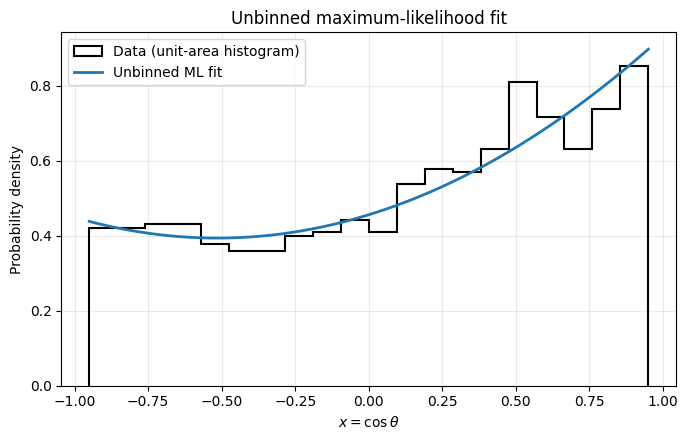

In [13]:
# TODO 1: extract a_fit and b_fit from m.values.
# TODO 2: evaluate pdf on a grid spanning the fit range.
# TODO 3: overlay that curve on a unit-area histogram of data.
a_fit, b_fit = ..., ...
x_plot = np.linspace(XMIN, XMAX, 500)
y_plot = ...

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(data, bins=20, range=(XMIN, XMAX), density=True, histtype="step",
        color="black", linewidth=1.5, label="Data")
ax.plot(x_plot, y_plot, linewidth=2, label="Unbinned ML fit")
ax.set(xlabel=r"$x=\cos\theta$", ylabel="Probability density",
       title="Unbinned maximum-likelihood fit")
ax.legend(); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()


## Step 6 — Explore the two-parameter likelihood


The contour plot shows how the fit quality changes when both parameters vary. The best-fit point is
the minimum of the NLL. For two parameters, the usual likelihood-ratio confidence regions correspond
to fixed increases in the NLL:

- 68.3% joint confidence: $\Delta(-\log L)=1.15$
- 95.0% joint confidence: $\Delta(-\log L)=3.00$
- 99.7% joint confidence: $\Delta(-\log L)=4.50$

These are **two-dimensional** confidence regions. They are not the same as drawing 1, 2, and 3
one-dimensional standard-deviation ellipses.


Two-parameter likelihood contours come directly from the fit’s negative log-likelihood (NLL). Each contour marks parameter pairs whose NLL is a fixed amount above the minimum. They show the fit’s actual shape, including bends or asymmetry.

### Your turn
Inspect the contour plot. Where is the minimum? What does the tilt of the contours tell you about the relationship between $a$ and $b$?


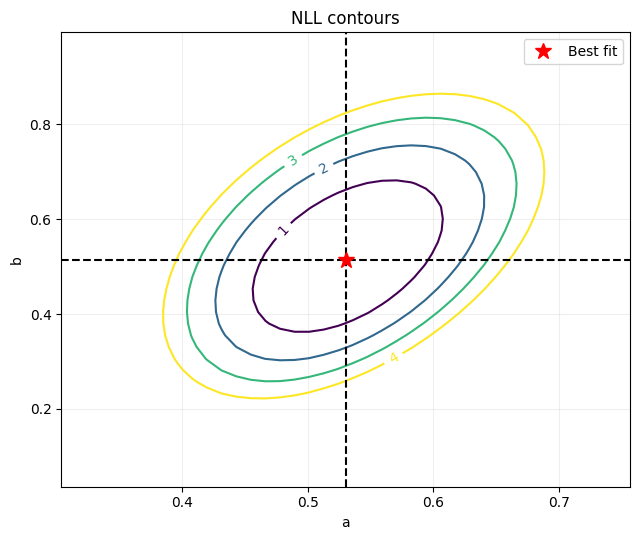

In [16]:
# TODO: draw a two-parameter likelihood contour for a and b.
# Hint: Minuit provides m.draw_contour("a", "b", ...).
# Add a marker for (a_fit, b_fit), axis labels, a legend, and a grid.
fig, ax = plt.subplots(figsize=(6.5, 5.5))
# m.draw_contour(...)
# ax.plot(...)
plt.show()


## Step 7 — Compare with covariance ellipses


Near the minimum, the NLL is approximately quadratic and the parameter uncertainties are described
by the covariance matrix. The ellipse below uses the covariance matrix and the chi-square quantiles
for **two** degrees of freedom.

Covariance-based confidence ellipses use the covariance matrix estimated at the best fit. They approximate the NLL locally as a quadratic, then draw ellipses from that approximation. They’re simpler to interpret, but can be inaccurate if the likelihood is strongly curved, non-elliptical, or close to a physical boundary.

In this notebook, the likelihood contours reflect the full fit; the ellipses summarize its local, near-minimum shape. If they agree closely, the quadratic approximation is reasonable in that region.

### Your turn
Construct confidence ellipses from the covariance matrix. Use the eigenvectors for orientation and eigenvalues for axis lengths. Give the 68.3%, 95.0%, and 99.7% ellipses distinct colors.


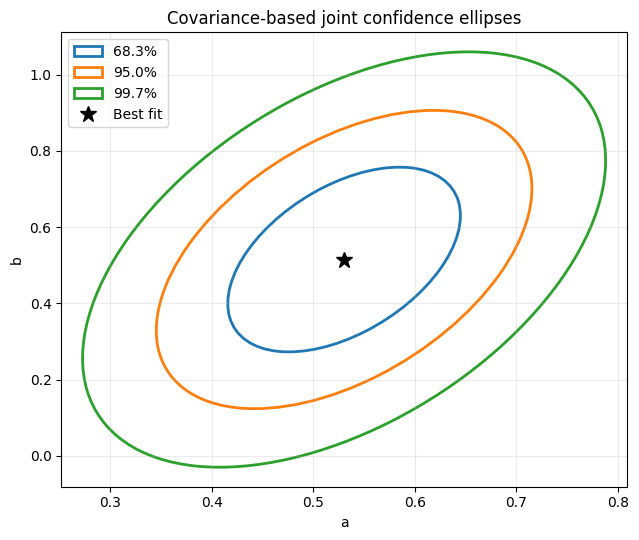

In [17]:
from matplotlib.patches import Ellipse
from scipy.stats import chi2

cov = np.asarray(m.covariance)
center = np.array([a_fit, b_fit])
eigenvalues, eigenvectors = np.linalg.eigh(cov)
if np.any(eigenvalues <= 0):
    raise ValueError("Covariance matrix is not positive definite.")

# TODO: find angle in degrees from the eigenvector for the largest eigenvalue.
angle = ...

fig, ax = plt.subplots(figsize=(6.5, 5.5))
confidence_levels = [(0.683, "68.3%", "tab:blue"),
                     (0.950, "95.0%", "tab:orange"),
                     (0.997, "99.7%", "tab:green")]
for confidence, label, color in confidence_levels:
    # TODO: scale = sqrt(chi2.ppf(confidence, df=2))
    # TODO: width and height are 2 * scale * sqrt(eigenvalues), largest first.
    # TODO: create an unfilled Ellipse centered at `center`, with `angle` and color.
    # TODO: add it to ax.
    pass

# TODO: mark center; label axes; add title, legend, grid; show plot.


## Step 8 — Record your conclusions

Answer in your own words before consulting the companion solutions notebook:

1. Does changing the histogram binning alter the fit? Explain.
2. Do different Minuit starting values converge to the same minimum?
3. Compare HESSE and MINOS uncertainties. Are the MINOS intervals symmetric?
4. Refit a reproducible half-size sample. How do the uncertainties change?
5. If the data are the toy sample, compare the fitted values with $a=0.35$, $b=0.25$.
6. Compare the likelihood contours with covariance ellipses. When is the ellipse approximation useful?

### References

- [iminuit documentation](https://iminuit.readthedocs.io/)
- [UnbinnedNLL documentation](https://iminuit.readthedocs.io/en/stable/reference.html#iminuit.cost.UnbinnedNLL)
